# Colab Intro


### Sumowanie ciągu geometrycznego

**Ciąg geometryczny** (progresja geometryczna) definiujemy jako dyskretną strukturę liczbową $(a_n)_{n \in \mathbb{N}_+}$, w której relacja między dwoma sąsiednimi wyrazami jest stała. Oznacza to, że iloraz dowolnego wyrazu (z wyjątkiem pierwszego) i wyrazu go poprzedzającego stanowi stałą wartość wielkościową $q \in \mathbb{R}$, zwaną ilorazem progresji:

$$\frac{a_{n+1}}{a_n} = q \quad \text{dla każdego } n \ge 1$$

Wyznaczanie **sumy częściowej $S_n$** sprowadza się do agregacji początkowych $n$ elementów tego zestawu danych. Proces ten można opisać za pomocą operatora sumowania (notacji sigma):

$$S_n = \sum_{k=1}^{n} a_k$$

#### Analityczne wzory jawne:

W celu optymalizacji obliczeń, powyższą sumę skończoną transformuje się do postaci zwartej, której struktura zależy od wartości parametru $q$:

1. **Dla ilorazu relacji różnego od jedności ($q \neq 1$):**
   Wartość skupiona ciągu jest funkcją wyrazu początkowego oraz potęgi ilorazu:
   $$S_n = a_1 \frac{q^n - 1}{q - 1}$$

2. **Dla przypadku osobliwego ($q = 1$):**
   Gdy struktura redukuje się do ciągu stałego, agregacja przyjmuje postać liniową:
   $$S_n = n \cdot a_1$$

*Oznaczenia zmiennych:*
* $a_1$ – warunek początkowy (pierwszy człon ciągu),
* $q$ – stała multiplikatywna (iloraz progresji),
* $n$ – moc zbioru sumowanych elementów (indeks końcowy).


In [1]:
2+2

4

In [6]:
import math

# Obliczenie wartości pi podniesionej do potęgi pi
wynik = math.pi ** math.pi

# Wyświetlenie wyniku
print(f"Wynik pi^pi w przybliżeniu: {wynik}")


Wynik pi^pi w przybliżeniu: 36.4621596072079


In [7]:
# Obliczenie sumy kwadratów liczb od 1 do 100
suma_kwadratow = sum(x**2 for x in range(1, 101))

# Eleganckie wyświetlenie wyniku
print(f"Suma kwadratów liczb od 1 do 100 wynosi: {suma_kwadratow:,}".replace(",", " "))


Suma kwadratów liczb od 1 do 100 wynosi: 338 350


In [8]:
# 1. Obliczenie sumy kwadratów
suma_kwadratow = sum(x**2 for x in range(1, 101))

# 2. Zapis wyniku do pliku tekstowego w głównym katalogu roboczym Colaba
nazwa_pliku = "colab_wynik.txt"

with open(nazwa_pliku, "w", encoding="utf-8") as plik:
    plik.write(f"Suma kwadratów liczb od 1 do 100 wynosi: {suma_kwadratow}\n")

print(f"Plik '{nazwa_pliku}' został zapisany.")


Plik 'colab_wynik.txt' został zapisany.


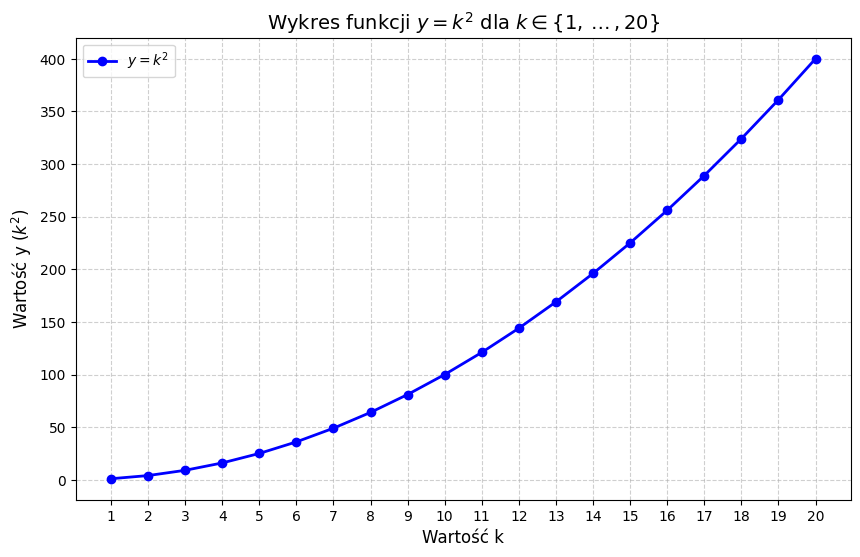

Plik 'wykres.png' został zapisany.


In [13]:
import matplotlib.pyplot as plt

# 1. Przygotowanie danych (k od 1 do 20 oraz y = k^2)
k_values = list(range(1, 21))
y_values = [k**2 for k in k_values]

# 2. Tworzenie wykresu
plt.figure(figsize=(10, 6))
plt.plot(k_values, y_values, marker='o', color='b', linestyle='-', linewidth=2, label='$y = k^2$')

# 3. Dodanie etykiet, tytułu i siatki (użycie r'...' zapobiega SyntaxWarning)
plt.title(r'Wykres funkcji $y = k^2$ dla $k \in \{1, \dots, 20\}$', fontsize=14)
plt.xlabel('Wartość k', fontsize=12)
plt.ylabel('Wartość y ($k^2$)', fontsize=12)
plt.xticks(range(1, 21))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# 4. Zapis do pliku PNG (przed plt.show())
nazwa_wykresu = "wykres.png"
plt.savefig(nazwa_wykresu, dpi=300, bbox_inches='tight')

# 5. Wyświetlenie wykresu w Colabie
plt.show()

# Poprawiono odwołanie do zmiennej - teraz wskazuje na nazwa_wykresu
print(f"Plik '{nazwa_wykresu}' został zapisany.")

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import base64

# 1. Parametry fizyczne wahadła i konfiguracja czasu
g = 9.81      # Przyspieszenie ziemskie [m/s^2]
L = 1.0       # Długość ramienia wahadła [m]
theta0 = 0.5  # Kąt początkowy wychylenia [rad] (ok. 30 stopni)
omega = np.sqrt(g / L)  # Częstość kołowa

# Tworzenie osi czasu: 5 sekund animacji przy 30 klatkach na sekundę (fps)
fps = 30
t_max = 5
t = np.linspace(0, t_max, t_max * fps)

# Rozwiązanie analityczne dla małych drgań: theta(t) = theta0 * cos(omega * t)
theta = theta0 * np.cos(omega * t)

# Konwersja współrzędnych biegunowych na kartezjańskie (pozycja masy wahadła)
x = L * np.sin(theta)
y = -L * np.cos(theta)

# 2. Przygotowanie wykresu do animacji
fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.2 * L, 1.2 * L)
ax.set_ylim(-1.2 * L, 0.2 * L)
ax.set_aspect('equal')
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_title("Animacja Wahadła Matematycznego", fontsize=14)

# Elementy rysunku: ramię (linia) i masa (kropka)
line, = ax.plot([], [], 'o-', lw=3, color='royalblue', markersize=15)

# Funkcja inicjalizująca wykres
def init():
    line.set_data([], [])
    return line,

# Funkcja aktualizująca pozycję wahadła w każdej klatce (frame)
def update(frame):
    # Pozycja od punktu zawieszenia (0,0) do punktu (x[frame], y[frame])
    this_x = [0, x[frame]]
    this_y = [0, y[frame]]
    line.set_data(this_x, this_y)
    return line,

# 3. Tworzenie animacji przy użyciu FuncAnimation
anim = FuncAnimation(fig, update, frames=len(t), init_func=init, blit=True)
plt.close() # Zamyka statyczny wykres, aby nie dublować obrazu

# 4. Zapis animacji do pliku video.mp4 za pomocą writera 'ffmpeg'
# (Google Colab ma domyślnie zainstalowane środowisko ffmpeg)
nazwa_wideo = "video.mp4"
anim.save(nazwa_wideo, writer='ffmpeg', fps=fps, extra_args=['-vcodec', 'libx264'])
print(f"Pomyślnie wygenerowano i zapisano plik: '{nazwa_wideo}'")

# 5. Osadzenie i wyświetlenie pliku wideo w komórce Colaba (HTML5)
video_file = open(nazwa_wideo, "rb").read()
video_encoded = base64.b64encode(video_file).decode("ascii")
video_html = f'''
<video width="500" height="500" controls autoplay loop>
    <source src="data:video/mp4;base64,{video_encoded}" type="video/mp4">
    Twój edytor nie obsługuje znacznika wideo HTML5.
</video>
'''
HTML(video_html)


Pomyślnie wygenerowano i zapisano plik: 'video.mp4'


Rozpoczynanie konwersji MP4 do GIF...
MoviePy - Building file video.gif with imageio.



Sukces! Plik animowany został zapisany pod nazwą: 'video.gif'


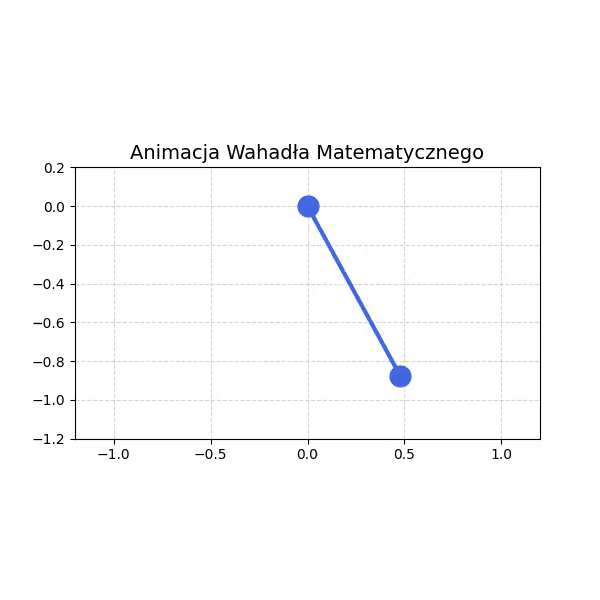

In [17]:
import warnings
# Wyciszenie ostrzeżeń typu SyntaxWarning pochodzących z zewnętrznych pakietów
warnings.filterwarnings("ignore", category=SyntaxWarning)

from moviepy.editor import VideoFileClip

# 1. Definicja ścieżek do plików
ścieżka_mp4 = "video.mp4"
ścieżka_gif = "video.gif"

print("Rozpoczynanie konwersji MP4 do GIF...")

try:
    # 2. Wczytanie pliku wideo i zapis do formatu GIF
    with VideoFileClip(ścieżka_mp4) as clip:
        # Optymalizacja: stosujemy domyślną paletę kolorów dla lepszej jakości GIF-a
        clip.write_gif(ścieżka_gif, fps=30, program='imageio')

    print(f"\nSukces! Plik animowany został zapisany pod nazwą: '{ścieżka_gif}'")

except FileNotFoundError:
    print(f"Błąd: Nie znaleziono pliku źródłowego '{ścieżka_mp4}' w katalogu roboczym.")
    print("Upewnij się, że komórka generująca plik MP4 została uruchomiona jako pierwsza!")

from IPython.display import Image, display

# Wyświetlenie zapisanego pliku GIF w notebooku
display(Image(filename="video.gif"))

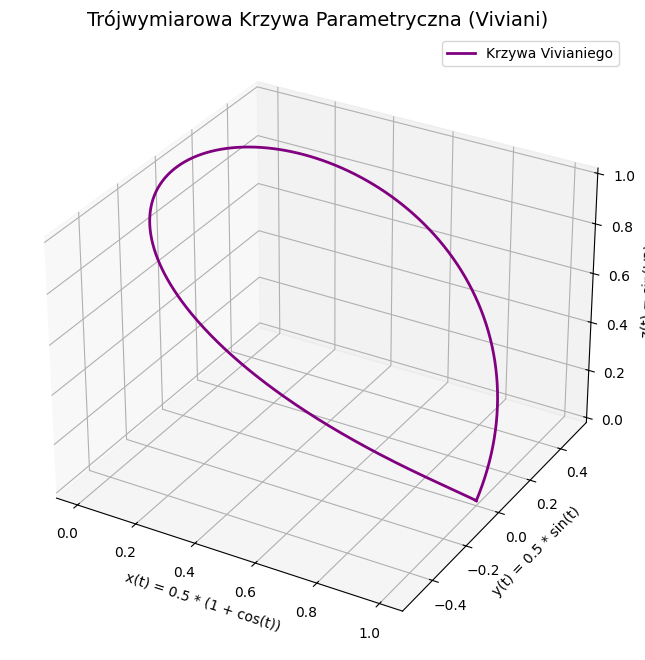

Zmodyfikowana funcja: 'parametric_curve.png' 


In [19]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 1. Nowe równania parametryczne (Krzywa Vivianiego)
t = np.linspace(0, 2 * np.pi, 500)
# Promień sfery R = 1
x = 0.5 * (1 + np.cos(t))
y = 0.5 * np.sin(t)
z = np.sin(t / 2)

# 2. Tworzenie wykresu 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Rysowanie zmodyfikowanej krzywej
ax.plot(x, y, z, label="Krzywa Vivianiego", color='purple', linewidth=2)

# 3. Opis wykresu i osi
ax.set_title("Trójwymiarowa Krzywa Parametryczna (Viviani)", fontsize=14)
ax.set_xlabel("x(t) = 0.5 * (1 + cos(t))")
ax.set_ylabel("y(t) = 0.5 * sin(t)")
ax.set_zlabel("z(t) = sin(t/2)")
ax.legend()

# 4. Zapis wykresu do pliku graficznego (wywołany przed plt.show())
nazwa_pliku = "parametric_curve.png"
plt.savefig(nazwa_pliku, dpi=300, bbox_inches='tight')

# 5. Wyświetlenie wykresu w notebooku
plt.show()

print(f"Zmodyfikowana funcja: '{nazwa_pliku}' ")
